In [1]:
# ==========================================
# 1. โหลดไลบรารีและกำหนดค่าการแสดงผล
# ==========================================

import os
import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", "{:,.2f}".format)

# ดาวน์โหลดชุดข้อมูลเวอร์ชันล่าสุดลงเครื่องและเก็บตำแหน่งโฟลเดอร์ไว้ในตัวแปร path
path = kagglehub.dataset_download("olistbr/brazilian-ecommerce")
print("Path to dataset files:", path)

# อ่านไฟล์ CSV แต่ละตารางจากโฟลเดอร์ path เข้าสู่ตัวแปร DataFrame
orders = pd.read_csv(f"{path}/olist_orders_dataset.csv")  # ตารางคำสั่งซื้อหลัก
order_items = pd.read_csv(f"{path}/olist_order_items_dataset.csv")  # ตารางรายการสินค้าในแต่ละคำสั่งซื้อ
payments = pd.read_csv(f"{path}/olist_order_payments_dataset.csv")  # ตารางข้อมูลการชำระเงิน
reviews = pd.read_csv(f"{path}/olist_order_reviews_dataset.csv")  # ตารางรีวิวและคะแนนความพึงพอใจจากลูกค้า
customers = pd.read_csv(f"{path}/olist_customers_dataset.csv")  # ตารางข้อมูลลูกค้าและพื้นที่/รัฐของลูกค้า
sellers = pd.read_csv(f"{path}/olist_sellers_dataset.csv")  # ตารางข้อมูลผู้ขายและพื้นที่/รัฐของผู้ขาย

# ตรวจสอบความถูกต้องและขนาดของแต่ละ DataFrame (จำนวนแถว, จำนวนคอลัมน์)
print("\nData loaded successfully:")
print(f"- Orders: {orders.shape}")
print(f"- Order Items: {order_items.shape}")
print(f"- Payments: {payments.shape}")
print(f"- Reviews: {reviews.shape}")
print(f"- Customers: {customers.shape}")
print(f"- Sellers: {sellers.shape}")

Path to dataset files: C:\Users\User\.cache\kagglehub\datasets\olistbr\brazilian-ecommerce\versions\2

Data loaded successfully:
- Orders: (99441, 8)
- Order Items: (112650, 7)
- Payments: (103886, 5)
- Reviews: (99224, 7)
- Customers: (99441, 5)
- Sellers: (3095, 4)


In [2]:
# ==========================================
# 2. ทำความสะอาดข้อมูล (Data Cleaning)
# ==========================================

# กำหนดรายชื่อคอลัมน์วันที่และเวลาที่ต้องใช้งานในการวิเคราะห์ระยะเวลา Order-to-Delivery
time_columns = [
    "order_purchase_timestamp",  # วัน-เวลาที่ลูกค้ากดยืนยันสั่งซื้อ
    "order_approved_at",  # วัน-เวลาที่การชำระเงินได้รับการอนุมัติ
    "order_delivered_carrier_date",  # วัน-เวลาที่ร้านค้าส่งมอบพัสดุให้บริษัทขนส่ง
    "order_delivered_customer_date",  # วัน-เวลาที่พัสดุส่งถึงมือลูกค้าจริง
    "order_estimated_delivery_date",  # วันที่ประมาณการที่คาดว่าจะส่งถึงลูกค้า
]

# แปลงชนิดข้อมูล (Data Type) ในคอลัมน์เวลาทั้งหมดจากข้อความ (String) ให้เป็น Datetime ของ pandas
# เพื่อให้สามารถนำมาลบกันเพื่อหาระยะเวลา (Duration) ได้
for col in time_columns:
    orders[col] = pd.to_datetime(orders[col])

# ตรวจสอบว่ามี order_id ซ้ำกันในตาราง orders หรือไม่ โดยดูผลรวมของแถวที่ duplicated (ควรเป็น 0)
print("Duplicate order_id:", orders["order_id"].duplicated().sum())

# กำหนดคอลัมน์เวลาสำคัญ 4 จุดที่จำเป็นต้องมีข้อมูลครบถ้วนสำหรับคำนวณ Stage ต่างๆ
key_cols = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
]

# กรองเฉพาะคำสั่งซื้อที่มีสถานะเป็น 'delivered' (จัดส่งสำเร็จแล้ว)
delivered = orders[orders["order_status"] == "delivered"]

# ตัดแถวที่มีค่าว่าง (Missing / NaN) ในคอลัมน์สำคัญออก แล้วใช้ .copy() เพื่อสร้าง DataFrame ใหม่แบบไม่ติด View
df_o2c = delivered.dropna(subset=key_cols).copy()

# สร้าง DataFrame สรุปขั้นตอนการทำความสะอาดข้อมูล (Data Cleaning Log) เพื่อดูจำนวนแถวที่หายไปในแต่ละขั้นตอน
cleaning_log = pd.DataFrame({
    "step": [
        "All orders",
        "Status = delivered",
        "After dropping missing timestamps",
    ],
    "rows": [len(orders), len(delivered), len(df_o2c)],
})

# คำนวณจำนวนแถวที่ถูกคัดทิ้งในแต่ละสเต็ป โดยใช้ผลต่างย้อนหลัง (.diff()) และแปลงเป็นค่าบวก
cleaning_log["removed"] = -cleaning_log["rows"].diff().fillna(0).astype(int)

# แสดงจำนวนคำสั่งซื้อสุทธิที่พร้อมสำหรับการนำไปวิเคราะห์กระบวนการ (Order-to-Delivery)
print(f"\nTotal orders ready for process analysis: {len(df_o2c):,}")

# แสดงตาราง Cleaning Log ออกมาในรูปแบบ HTML บน Jupyter Notebook
display(cleaning_log)

Duplicate order_id: 0

Total orders ready for process analysis: 96,455


,step,rows,removed
0,All orders,99441,0
1,Status = delivered,96478,2963
2,After dropping missing timestamps,96455,23


In [3]:
# ==========================================
# 3. คำนวณระยะเวลาในแต่ละ Stage และ Flag สถานะส่งช้า
# ==========================================

# กำหนดค่าคงที่ 86,400 วินาที (60 วิ * 60 นาที * 24 ชม.) ใช้แปลงค่าผลต่างเวลาเป็นหน่วย "วัน" (Days)
SEC_PER_DAY = 86400

# Stage 1: เวลาตั้งแต่กดสั่งซื้อจนกระทั่งระบบอนุมัติการชำระเงิน
df_o2c["days_to_approve"] = (
    df_o2c["order_approved_at"] - df_o2c["order_purchase_timestamp"]
).dt.total_seconds() / SEC_PER_DAY

# Stage 2: เวลาตั้งแต่ชำระเงินสำเร็จจนถึงส่งมอบให้ขนส่ง (สะท้อนประสิทธิภาพฝั่งร้านค้า/Seller Dispatch)
df_o2c["days_to_carrier"] = (
    df_o2c["order_delivered_carrier_date"] - df_o2c["order_approved_at"]
).dt.total_seconds() / SEC_PER_DAY

# Stage 3: เวลาตั้งแต่ขนส่งรับพัสดุไปจนถึงส่งถึงมือลูกค้า (สะท้อนประสิทธิภาพฝั่งขนส่ง/Carrier Transit)
df_o2c["days_to_customer"] = (
    df_o2c["order_delivered_customer_date"]
    - df_o2c["order_delivered_carrier_date"]
).dt.total_seconds() / SEC_PER_DAY

# Total Cycle Time: ระยะเวลารวมทั้งหมดตั้งแต่เริ่มสั่งซื้อจนได้รับสินค้าสำเร็จ
df_o2c["total_cycle_time"] = (
    df_o2c["order_delivered_customer_date"]
    - df_o2c["order_purchase_timestamp"]
).dt.total_seconds() / SEC_PER_DAY

# คำนวณจำนวนวันที่ส่งล่าช้ากว่ากำหนดส่งโดยประมาณ (Delay Days)
# ใช้ .dt.normalize() เพื่อตัดเศษเวลาชั่วโมง/นาที/วินาทีออก ให้เปรียบเทียบเฉพาะระดับวันที่
# และดึงค่าเป็นจำนวนวันเต็ม (.dt.days)
df_o2c["delay_days"] = (
    df_o2c["order_delivered_customer_date"].dt.normalize()
    - df_o2c["order_estimated_delivery_date"].dt.normalize()
).dt.days

# สร้าง Flag ระบุสถานะส่งช้า (1 คือส่งช้ากว่ากำหนด เพราะ delay_days > 0, 0 คือส่งตรงเวลาหรือส่งก่อนกำหนด)
df_o2c["is_late"] = (df_o2c["delay_days"] > 0).astype(int)

# ตรวจสอบความถูกต้องของข้อมูล (Validation): ลบแถวที่เกิดข้อผิดพลาดด้านเวลาจนทำให้ระยะเวลาติดลบ (< 0)
stage_cols = [
    "days_to_approve",
    "days_to_carrier",
    "days_to_customer",
    "total_cycle_time",
]
before_drop = len(df_o2c)

# กรองเลือกเฉพาะแถวที่ทุกคอลัมน์ใน stage_cols มีค่ามากกว่าหรือเท่ากับ 0 (.all(axis=1))
df_o2c = df_o2c[(df_o2c[stage_cols] >= 0).all(axis=1)].copy()

# พิมพ์รายงานจำนวนแถวข้อมูลเวลาผิดปกติที่ถูกตัดออก และยอดคงเหลือสุดท้ายที่ผ่านการตรวจสอบ
print(f"Removed {before_drop - len(df_o2c):,} rows with negative durations")
print(f"Final validated orders: {len(df_o2c):,}")

Removed 1,373 rows with negative durations
Final validated orders: 95,082


=== Order Stage Duration Breakdown ===


,Mean (Days),Median (Days),90th Percentile,Share of Mean Total (%),Share of Median Total (%)
days_to_approve,0.40,0.01,1.39,3.19,0.14
days_to_carrier,2.85,1.85,6.02,22.60,18.00
days_to_customer,9.36,7.11,18.95,74.21,69.23


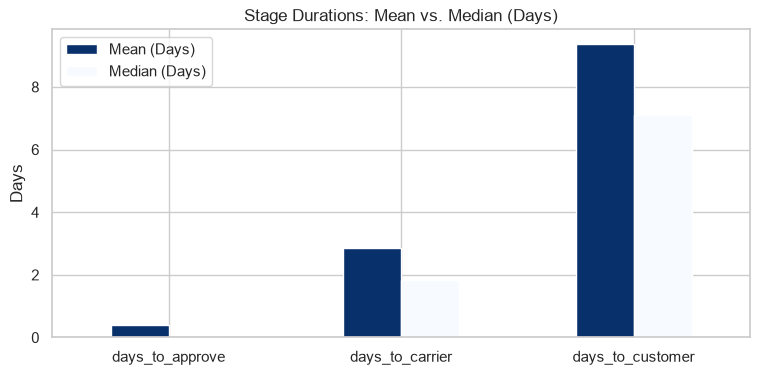

Late delivery rate: 6.8%
Median total cycle time: 10.3 days


In [4]:
# ==========================================
# Q1: ขั้นตอนไหนใช้เวลานานที่สุด (Bottleneck Analysis)
# ==========================================

# รายชื่อคอลัมน์ขั้นตอนการจัดส่งสินค้าเพื่อใช้รวมสถิติ
stages = ["days_to_approve", "days_to_carrier", "days_to_customer"]

# สรุปค่าสถิติ Mean (ค่าเฉลี่ย), Median (มัธยฐาน), และ Percentile ที่ 90 (ค่าที่ครอบคลุม 90% ของออเดอร์)
# ใช้ .T (Transpose) เพื่อสลับแถวกับคอลัมน์ให้อ่านง่าย
summary = df_o2c[stages].agg(["mean", "median", lambda x: x.quantile(0.90)]).T
summary.columns = ["Mean (Days)", "Median (Days)", "90th Percentile"]

# คำนวณสัดส่วนเปอร์เซ็นต์ของแต่ละขั้นตอนเทียบกับเวลารวมทั้งหมด ทั้งในมุมของ Mean และ Median
summary["Share of Mean Total (%)"] = (
    summary["Mean (Days)"] / df_o2c["total_cycle_time"].mean() * 100
)
summary["Share of Median Total (%)"] = (
    summary["Median (Days)"] / df_o2c["total_cycle_time"].median() * 100
)

# แสดงตารางสถิติเปรียบเทียบระยะเวลาในแต่ละขั้นตอน
print("=== Order Stage Duration Breakdown ===")
display(summary.round(2))

# วาดกราฟแท่งเปรียบเทียบระหว่าง Mean และ Median เพื่อดูความเบ้ (Skewness) จากค่าผิดปกติ (Outliers)
summary[["Mean (Days)", "Median (Days)"]].plot(
    kind="bar", figsize=(9, 4), rot=0, colormap="Blues_r"
)
plt.title("Stage Durations: Mean vs. Median (Days)")
plt.ylabel("Days")
plt.show()

# คำนวณและแสดงอัตราส่วนคำสั่งซื้อที่จัดส่งล่าช้าทั้งหมด (Late Delivery Rate)
print(f"Late delivery rate: {df_o2c['is_late'].mean():.1%}")

# แสดงเวลามัธยฐานรวมในการจัดส่งคำสั่งซื้อทั้งหมด (Median Total Cycle Time)
print(f"Median total cycle time: {df_o2c['total_cycle_time'].median():.1f} days")

,delay_bucket,Order_Count,Avg_Review_Score
0,On time / Early,88573,4.29
1,1-3 days late,1860,3.29
2,4-7 days late,1794,2.11
3,8-14 days late,1476,1.67
4,>14 days late,1379,1.72


C:\Users\User\AppData\Local\Temp\ipykernel_1656\1654505233.py:40: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


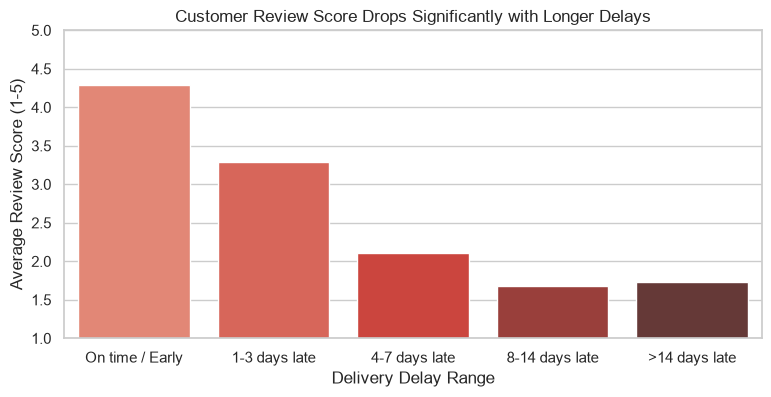

In [5]:
# ==========================================
# Q2: ความล่าช้าส่งผลต่อ Review Score อย่างไร
# ==========================================

# คำนวณคะแนนรีวิวเฉลี่ยต่อ order_id เพื่อแก้ปัญหา 1 คำสั่งซื้ออาจมีลูกค้าเข้ามารีวิวมากกว่า 1 ครั้ง
rev = reviews.groupby("order_id", as_index=False)["review_score"].mean()

# ทำการ Left Join นำคะแนนรีวิวกลับเข้ามาเชื่อมกับตารางคำสั่งซื้อ df_o2c
df_rev = df_o2c.merge(rev, on="order_id", how="left")

# ใช้ pd.cut จัดกลุ่มจำนวนวันที่ส่งช้า (delay_days) ออกเป็นช่วงๆ (Bucket)
# กำหนด bins ช่วง: <=0 (ทันกำหนด), 1-3 วัน, 4-7 วัน, 8-14 วัน, และมากกว่า 14 วัน
df_rev["delay_bucket"] = pd.cut(
    df_rev["delay_days"],
    bins=[-999, 0, 3, 7, 14, 999],
    labels=[
        "On time / Early",
        "1-3 days late",
        "4-7 days late",
        "8-14 days late",
        ">14 days late",
    ],
)

# จัดกลุ่มตามช่วงความล่าช้าเพื่อนับจำนวนออเดอร์ และหาค่าเฉลี่ยของคะแนนรีวิวในแต่ละช่วง
bucket_summary = (
    df_rev.groupby("delay_bucket", observed=True)
    .agg(
        Order_Count=("order_id", "count"),
        Avg_Review_Score=("review_score", "mean"),
    )
    .reset_index()
)

# แสดงตารางสรุปจำนวนออเดอร์และคะแนนรีวิวเฉลี่ยตาม Bucket
display(bucket_summary.round(2))

# สร้างกราฟแท่งแสดงแนวโน้มคะแนนรีวิวที่ลดลงตามระดับความล่าช้าในการจัดส่ง
plt.figure(figsize=(9, 4))
sns.barplot(
    data=bucket_summary,
    x="delay_bucket",
    y="Avg_Review_Score",
    palette="Reds_d",  # ใช้โทนสีแดงเพื่อสื่อถึงความวิกฤต/ปัญหา
)
plt.title("Customer Review Score Drops Significantly with Longer Delays")
plt.xlabel("Delivery Delay Range")
plt.ylabel("Average Review Score (1-5)")
plt.ylim(1, 5)  # กำหนดสเกลแกน Y ให้อยู่ในช่วง 1 ถึง 5 ดาว ตามระบบคะแนนรีวิว
plt.show()

In [6]:
# ==========================================
# Q3: ความเร็วในการส่งและอัตราส่งช้าแยกตามรัฐ (State Analysis)
# ==========================================

# เชื่อมตารางเพื่อดึงข้อมูลรัฐปลายทางของผู้รับสินค้า (customer_state) โดยใช้ customer_id เป็นคีย์เชื่อม
df_state = df_rev.merge(
    customers[["customer_id", "customer_state"]], on="customer_id", how="left"
)

# จัดกลุ่มข้อมูลตามรัฐของผู้รับ (customer_state) แล้วสรุปสถิติต่างๆ
state_summary = (
    df_state.groupby("customer_state")
    .agg(
        total_orders=("order_id", "count"),  # ยอดสั่งซื้อรวม
        avg_cycle_days=("total_cycle_time", "mean"),  # เวลาเฉลี่ยที่ใช้ในการส่ง
        median_cycle_days=("total_cycle_time", "median"),  # เวลามัธยฐานที่ใช้ในการส่ง
        late_delivery_rate=("is_late", "mean"),  # สัดส่วนออเดอร์ที่ส่งล่าช้า
        avg_review_score=("review_score", "mean"),  # คะแนนรีวิวเฉลี่ยของรัฐนั้น
    )
    .reset_index()
)

# แปลงอัตราส่งช้าเป็นค่าร้อยละ (%)
state_summary["late_delivery_rate"] *= 100

# กรองตัดรัฐที่มีจำนวนออเดอร์น้อยเกินไปออก (เลือกเฉพาะรัฐที่มีคำสั่งซื้อตั้งแต่ 100 ออเดอร์ขึ้นไป) เพื่อให้มีความน่าเชื่อถือทางสถิติ
state_summary = state_summary[state_summary["total_orders"] >= 100]

# เรียงลำดับจากรัฐที่ใช้เวลาจัดส่งเฉลี่ยนานที่สุดลงไปหาน้อยที่สุด
state_summary = state_summary.sort_values("avg_cycle_days", ascending=False)

# แสดงรายชื่อ 10 รัฐแรกที่ใช้เวลาจัดส่งนานที่สุด (Slowest Fulfillment)
print("=== Top 10 States with Slowest Fulfillment ===")
display(state_summary.head(10).round(2))

=== Top 10 States with Slowest Fulfillment ===


,customer_state,total_orders,avg_cycle_days,median_cycle_days,late_delivery_rate,avg_review_score
2,AM,144,26.43,25.86,2.78,4.26
1,AL,393,24.38,22.33,21.12,3.87
13,PA,936,23.81,21.09,11.11,3.91
9,MA,704,21.68,19.24,17.76,3.84
24,SE,333,21.59,18.05,15.32,3.91
5,CE,1259,21.40,18.23,13.98,3.94
14,PB,509,20.51,18.20,10.41,4.07
16,PI,469,19.59,16.38,14.07,4.00
20,RO,242,19.42,17.64,2.89,4.16
4,BA,3210,19.38,16.95,12.18,3.93


In [7]:
# ==========================================
# Q4: พฤติกรรมการชำระเงิน (Payment Behavior)
# ==========================================

# กรองรายการที่ไม่ได้ระบุประเภทการชำระเงิน ('not_defined') ออกจากชุดข้อมูล
pay_clean = payments[payments["payment_type"] != "not_defined"]

# จัดกลุ่มข้อมูลตามประเภทการชำระเงิน (payment_type) เพื่อสรุปสถิติสำคัญ
pay_summary = (
    pay_clean.groupby("payment_type")
    .agg(
        transaction_count=("order_id", "count"),  # จำนวนธุรกรรม
        total_revenue=("payment_value", "sum"),  # มูลค่ายอดเงินรวม
        avg_payment_value=("payment_value", "mean"),  # ยอดจ่ายเฉลี่ยต่อธุรกรรม
        avg_installments=("payment_installments", "mean"),  # จำนวนงวดผ่อนเฉลี่ย
    )
    .reset_index()
)

# คำนวณส่วนแบ่งการตลาดเป็นเปอร์เซ็นต์ (% Share) จากจำนวนธุรกรรมทั้งหมด
pay_summary["share_%"] = (
    pay_summary["transaction_count"] / pay_summary["transaction_count"].sum() * 100
)

# เรียงลำดับช่องทางการชำระเงินจากจำนวนธุรกรรมมากที่สุดไปหาน้อยที่สุด และรีเซ็ต Index ใหม่
pay_summary = pay_summary.sort_values(
    "transaction_count", ascending=False
).reset_index(drop=True)

# แสดงตารางวิเคราะห์พฤติกรรมการชำระเงิน
print("=== Payment Method Analysis ===")
display(pay_summary.round(2))

=== Payment Method Analysis ===


,payment_type,transaction_count,total_revenue,avg_payment_value,avg_installments,share_%
0,credit_card,76795,"12,542,084.19",163.32,3.51,73.92
1,boleto,19784,"2,869,361.27",145.03,1.00,19.04
2,voucher,5775,"379,436.87",65.70,1.00,5.56
3,debit_card,1529,"217,989.79",142.57,1.00,1.47


In [8]:
# ==========================================
# Q5: ผู้ขายที่ส่งล่าช้าบ่อย และผลกระทบต่อยอดเงิน (Seller Late Analysis)
# ==========================================

# นำตาราง order_items มาเชื่อมกับตารางคำสั่งซื้อ df_o2c เพื่อดูว่าสินค้านั้นเป็นของผู้ขายคนใด และออเดอร์นั้นส่งช้าหรือไม่
items_with_stages = order_items.merge(
    df_o2c[["order_id", "is_late", "days_to_carrier", "days_to_customer"]],
    on="order_id",
    how="inner",
)

# สรุปข้อมูลในระดับ (seller_id, order_id) รวมราคาเฉพาะสินค้าของผู้ขายรายนั้นในแต่ละออเดอร์
# ป้องกันปัญหายอดเงินซ้ำซ้อนกรณีที่ออเดอร์เดียวมีสินค้าหลายชิ้น
seller_orders = (
    items_with_stages.groupby(["seller_id", "order_id"])
    .agg(
        revenue=("price", "sum"),  # ยอดขายของผู้ขายในออเดอร์นั้น
        is_late=("is_late", "first"),  # สถานะส่งช้าของออเดอร์ (ใช้ค่าแรกเนื่องจากค่าเหมือนกัน)
        days_to_carrier=("days_to_carrier", "first"),  # วันที่ร้านค้าใช้เตรียมและมอบให้ขนส่ง
        days_to_customer=("days_to_customer", "first"),  # วันที่ขนส่งใช้นำพัสดุไปส่งลูกค้า
    )
    .reset_index()
)

# คำนวณยอดเงินที่ตกอยู่ในความเสี่ยง (Late Revenue): ถือเป็นยอดที่ส่งช้าเมื่อ is_late = 1
seller_orders["late_revenue"] = (
    seller_orders["revenue"] * seller_orders["is_late"]
)

# รวมสถิติในระดับผู้ขาย (seller_id)
seller_summary = (
    seller_orders.groupby("seller_id")
    .agg(
        total_orders=("order_id", "nunique"),  # จำนวนออเดอร์ทั้งหมดของร้านค้า
        late_rate=("is_late", "mean"),  # อัตราการจัดส่งล่าช้า
        avg_seller_dispatch_days=("days_to_carrier", "mean"),  # เวลาเฉลี่ยที่ร้านใช้แพ็กของส่งให้ขนส่ง
        avg_carrier_delivery_days=("days_to_customer", "mean"),  # เวลาเฉลี่ยที่ขนส่งใช้ส่งพัสดุถึงลูกค้า
        total_revenue=("revenue", "sum"),  # ยอดขายรวมทั้งหมดของร้านค้า
        total_late_revenue=("late_revenue", "sum"),  # ยอดขายรวมที่เกิดจากคำสั่งซื้อที่ส่งช้า
    )
    .reset_index()
)

# กรองเฉพาะร้านค้าที่มีออเดอร์ตั้งแต่ 30 รายการขึ้นไป เพื่อตัดร้านค้าขนาดเล็กมากออก
seller_summary = seller_summary[seller_summary["total_orders"] >= 30]

# แปลงอัตราส่งช้าเป็นเปอร์เซ็นต์ (%)
seller_summary["late_rate"] *= 100

# เรียงลำดับตามมูลค่ายอดเงินที่เสร็จสิ้นล่าช้า (total_late_revenue) จากมากไปน้อย
seller_summary = seller_summary.sort_values(
    "total_late_revenue", ascending=False
).reset_index(drop=True)

# แสดง 10 ร้านค้าแรกที่มีมูลค่ายอดเงินเสี่ยงจากปัญหาจัดส่งล่าช้าสูงที่สุด
print("=== Top 10 Sellers with Highest Revenue at Risk from Late Deliveries ===")
display(seller_summary.head(10).round(2))

=== Top 10 Sellers with Highest Revenue at Risk from Late Deliveries ===


,seller_id,total_orders,late_rate,avg_seller_dispatch_days,avg_carrier_delivery_days,total_revenue,total_late_revenue
0,4869f7a5dfa277a7dca6462dcf3b52b2,1112,10.61,2.38,12.35,"225,032.83","24,509.20"
1,4a3ca9315b744ce9f8e9374361493884,1756,9.79,2.39,11.77,"195,615.92","20,063.19"
2,7c67e1448b00f6e969d365cea6b010ab,972,9.16,11.38,10.46,"186,400.11","16,506.17"
3,fa1c13f2614d7b5c4749cbc52fecda94,574,9.23,2.37,10.66,"190,277.64","14,087.31"
4,7d13fca15225358621be4086e1eb0964,549,11.66,3.50,11.98,"110,777.20","14,042.44"
5,1025f0e2d44d7041d6cf58b6550e0bfa,898,7.91,3.82,8.18,"136,402.56","11,480.50"
6,da8622b14eb17ae2831f4ac5b9dab84a,1285,6.77,2.29,8.55,"157,099.97","11,180.10"
7,955fee9216a65b617aa5c0531780ce60,1232,6.25,1.74,8.60,"128,438.44","9,345.74"
8,f7ba60f8c3f99e7ee4042fdef03b70c4,216,13.89,2.11,10.82,"67,410.00","9,187.00"
9,7e93a43ef30c4f03f38b393420bc753a,313,4.79,2.46,8.53,"163,924.51","8,735.23"


In [9]:
# ==========================================
# 6. ส่งออกไฟล์ที่คลีนแล้วสำหรับนำไปสร้าง Power BI Dashboard
# ==========================================

# สร้างโฟลเดอร์ชื่อ 'output' หากยังไม่มี เพื่อใช้เป็นที่เก็บไฟล์ผลลัพธ์
os.makedirs("output", exist_ok=True)

# คำนวณยอดเงินรวมและช่องทางการจ่ายเงินหลักต่อ 1 order_id จากตาราง payments
order_payment_totals = (
    payments.groupby("order_id")
    .agg(
        total_order_value=("payment_value", "sum"),  # ยอดรวมการชำระเงินของคำสั่งซื้อ
        primary_payment_type=("payment_type", "first"),  # ประเภทช่องทางชำระเงินหลัก
    )
    .reset_index()
)

# นำยอดชำระเงินไปเชื่อม (Left Join) กับตารางคำสั่งซื้อ df_state เพื่อสร้างเป็น Fact Table สมบูรณ์
orders_fact_table = df_state.merge(
    order_payment_totals, on="order_id", how="left"
)

# บันทึกตารางสำคัญ 4 ตารางเป็นไฟล์ CSV ลงในโฟลเดอร์ output เพื่อนำไปเชื่อมต่อทำ Data Model ใน Power BI หรือ Tableau ต่อไป
# 1. ตาราง Fact ของคำสั่งซื้อ (Order-to-Delivery Process)
orders_fact_table.to_csv("output/fct_orders_o2c.csv", index=False)

# 2. ตาราง Dimension สรุปสถิติประสิทธิภาพการจัดส่งรายรัฐ
state_summary.to_csv("output/dim_state_summary.csv", index=False)

# 3. ตาราง Dimension สรุปประสิทธิภาพและยอดเงินกระทบของผู้ขาย
seller_summary.to_csv("output/dim_seller_summary.csv", index=False)

# 4. ตาราง Dimension สรุปภาพรวมช่องทางการชำระเงิน
pay_summary.to_csv("output/dim_payment_summary.csv", index=False)

# แจ้งเตือนเมื่อการประมวลผลและส่งออกไฟล์เสร็จสมบูรณ์
print("Successfully exported 4 curated tables to the ./output folder!")

Successfully exported 4 curated tables to the ./output folder!
